# SentinelML — Machine Learning-Based Network Intrusion Detection and Threat Analytics Platform
**IBM SkillsBuild Cyber Security BootCamp 2026 · Organised by BharatCares**

This notebook is the complete code deliverable. It covers: dataset loading and exploration, preprocessing, model training
(Random Forest + Logistic Regression), evaluation, traffic prediction, and threat-analytics visualisations.

**Dataset:** NSL-KDD (Canadian Institute for Cybersecurity, University of New Brunswick) — a genuine, public, labelled intrusion-detection
dataset. It is used here as the documented fallback because the recommended CIC-IDS2017 files were not downloadable in the build environment
(see README, section *Dataset*).

> **Educational-use disclaimer:** SentinelML is a learning prototype. It analyses *recorded, labelled* traffic records only. It does not monitor live
> networks, launch attacks, or replace professional security tools, and nothing here guarantees attack detection.

**How to run:** open this notebook from inside the `SentinelML` folder, then choose *Kernel → Restart & Run All*.

## 1. Setup — imports and configuration

In [1]:
import json, time, warnings, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42                       # fixed seed -> reproducible results
PROJECT_DIR  = Path.cwd()               # run the notebook from inside the SentinelML folder
DATA_DIR     = PROJECT_DIR / "data"
MODEL_DIR    = PROJECT_DIR / "models"
OUT_DIR      = PROJECT_DIR / "outputs"
for d in (DATA_DIR, MODEL_DIR, OUT_DIR):
    d.mkdir(exist_ok=True)

def save_fig(name):
    # Saves the current figure into outputs/ so the report and dashboard can reuse the real charts.
    plt.savefig(OUT_DIR / name, dpi=150, bbox_inches="tight")

print("Working folder:", PROJECT_DIR)

Matplotlib is building the font cache; this may take a moment.


Working folder: C:\Users\DELL\Desktop\SentinelML\SentinelML


## 2. Load the dataset
NSL-KDD ships as two files: `KDDTrain+.txt` (training) and `KDDTest+.txt` (official test set). The test set deliberately contains
attack types that never appear in training, which makes it a harder and more honest test of generalisation.

The files have no header row, so the 41 feature names + label + difficulty score are supplied below.
If the files are missing, the notebook tries to download them; if that fails, it prints manual instructions.

In [2]:
COLUMNS = ["duration","protocol_type","service","flag","src_bytes","dst_bytes","land","wrong_fragment","urgent","hot",
           "num_failed_logins","logged_in","num_compromised","root_shell","su_attempted","num_root","num_file_creations",
           "num_shells","num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count","srv_count",
           "serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate","same_srv_rate","diff_srv_rate",
           "srv_diff_host_rate","dst_host_count","dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",
           "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate","dst_host_srv_serror_rate",
           "dst_host_rerror_rate","dst_host_srv_rerror_rate","label","difficulty_level"]

BASE_URL = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/"   # public mirror of the NSL-KDD files

def ensure_file(name):
    path = DATA_DIR / name
    if path.exists():
        return path
    try:
        print(f"Downloading {name} ...")
        urllib.request.urlretrieve(BASE_URL + name, path)
        return path
    except Exception as err:
        raise FileNotFoundError(
            f"Could not find or download '{name}'.\n"
            f"Manual fix: download KDDTrain+.txt and KDDTest+.txt from https://www.unb.ca/cic/datasets/nsl.html "
            f"(or {BASE_URL}) and place them inside the folder: {DATA_DIR}\nOriginal error: {err}")

train_df = pd.read_csv(ensure_file("KDDTrain+.txt"), header=None, names=COLUMNS)
test_df  = pd.read_csv(ensure_file("KDDTest+.txt"),  header=None, names=COLUMNS)
print("Training file :", train_df.shape)
print("Test file     :", test_df.shape)
train_df.head()

Training file : (125973, 43)
Test file     : (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty_level
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,2,0.0,0.0,0.0,0.0,1.00,0.00,0.00,150,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,13,1,0.0,0.0,0.0,0.0,0.08,0.15,0.00,255,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,123,6,1.0,1.0,0.0,0.0,0.05,0.07,0.00,255,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,5,5,0.2,0.2,0.0,0.0,1.00,0.00,0.00,30,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,30,32,0.0,0.0,0.0,0.0,1.00,0.00,0.09,255,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


## 3. Data exploration

In [3]:
print("Records / columns (train):", train_df.shape)
print("Records / columns (test) :", test_df.shape)
print("\nColumn data types:\n", train_df.dtypes.value_counts())
print("\nMissing values  - train:", int(train_df.isna().sum().sum()), "| test:", int(test_df.isna().sum().sum()))
num_only = train_df.select_dtypes(include=[np.number])
print("Infinite values - train:", int(np.isinf(num_only).sum().sum()))
print("Duplicate rows  - train:", int(train_df.duplicated().sum()), "| test:", int(test_df.duplicated().sum()))
print("\nCategorical columns:", [c for c in ["protocol_type","service","flag"]])
print("Unique values -> protocol_type:", train_df.protocol_type.nunique(),
      "| service:", train_df.service.nunique(), "| flag:", train_df.flag.nunique())

Records / columns (train): (125973, 43)
Records / columns (test) : (22544, 43)

Column data types:
 int64      24
float64    15
str         4
Name: count, dtype: int64

Missing values  - train: 0 | test: 0
Infinite values - train: 0
Duplicate rows  - train: 0 | test: 0

Categorical columns: ['protocol_type', 'service', 'flag']
Unique values -> protocol_type: 3 | service: 70 | flag: 11


Duplicate rows  - train: 0 | test: 0

Categorical columns: ['protocol_type', 'service', 'flag']
Unique values -> protocol_type: 3 | service: 70 | flag: 11


In [4]:
print("Raw label counts in the TRAINING file:")
print(train_df["label"].value_counts().to_string())
print("\nLabels that appear in TEST but never in TRAIN (unseen attacks):")
unseen = sorted(set(test_df["label"]) - set(train_df["label"]))
print(unseen)

Raw label counts in the TRAINING file:
label
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2

Labels that appear in TEST but never in TRAIN (unseen attacks):
['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']


In [5]:
# Basic descriptive statistics for the numeric features
train_df.drop(columns=["difficulty_level"]).describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
duration,125973.0,287.14,2604.52,0.0,0.00,0.00,0.00,4.290800e+04
src_bytes,125973.0,45566.74,5870331.18,0.0,0.00,44.00,276.00,1.379964e+09
dst_bytes,125973.0,19779.11,4021269.15,0.0,0.00,0.00,516.00,1.309937e+09
land,125973.0,0.00,0.01,0.0,0.00,0.00,0.00,1.000000e+00
wrong_fragment,125973.0,0.02,0.25,0.0,0.00,0.00,0.00,3.000000e+00
urgent,125973.0,0.00,0.01,0.0,0.00,0.00,0.00,3.000000e+00
hot,125973.0,0.20,2.15,0.0,0.00,0.00,0.00,7.700000e+01
num_failed_logins,125973.0,0.00,0.05,0.0,0.00,0.00,0.00,5.000000e+00
logged_in,125973.0,0.40,0.49,0.0,0.00,0.00,1.00,1.000000e+00
num_compromised,125973.0,0.28,23.94,0.0,0.00,0.00,0.00,7.479000e+03


## 4. Label mapping (binary and attack-category)
* **Binary:** `normal` → 0 (Normal), everything else → 1 (Attack).
* **Category:** the standard NSL-KDD grouping of the 39 specific attack names into four families:
  **DoS** (denial of service), **Probe** (scanning/reconnaissance), **R2L** (remote-to-local access), **U2R** (user-to-root privilege escalation).

In [6]:
ATTACK_FAMILY = {
    "normal": "Normal",
    # Denial of Service
    **{a: "DoS" for a in ["back","land","neptune","pod","smurf","teardrop","apache2","udpstorm","processtable","worm","mailbomb"]},
    # Probing / reconnaissance
    **{a: "Probe" for a in ["satan","ipsweep","nmap","portsweep","mscan","saint"]},
    # Remote to Local
    **{a: "R2L" for a in ["guess_passwd","ftp_write","imap","phf","multihop","warezmaster","warezclient","spy",
                          "xlock","xsnoop","snmpguess","snmpgetattack","httptunnel","sendmail","named"]},
    # User to Root
    **{a: "U2R" for a in ["buffer_overflow","loadmodule","rootkit","perl","sqlattack","xterm","ps"]},
}
CATEGORY_ORDER = ["Normal", "DoS", "Probe", "R2L", "U2R"]
BINARY_NAMES   = ["Normal", "Attack"]

for df in (train_df, test_df):
    unmapped = set(df["label"]) - set(ATTACK_FAMILY)
    assert not unmapped, f"Unmapped labels found: {unmapped}"   # fail loudly instead of silently mislabelling
    df["category"]  = df["label"].map(ATTACK_FAMILY)
    df["is_attack"] = (df["label"] != "normal").astype(int)

print("TRAIN category counts:\n", train_df["category"].value_counts().reindex(CATEGORY_ORDER).to_string())
print("\nTEST category counts:\n",  test_df["category"].value_counts().reindex(CATEGORY_ORDER).to_string())

TRAIN category counts:
 category
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52

TEST category counts:
 category
Normal    9711
DoS       7460
Probe     2421
R2L       2885
U2R         67


## 5. Preprocessing and leakage prevention
Decisions (each one protects the honesty of the evaluation):

1. **`difficulty_level` is dropped** — it is a score added by the dataset authors, not a property of the traffic, so using it would be unsuitable/leaky.
2. **Labels are never features** — `label`, `category`, and `is_attack` are removed from the input matrix.
3. **Exact duplicate rows in training are removed *before* splitting**, so the same record cannot land in both train and validation.
4. **Split first, fit later** — the training data is split (stratified by category) *before* any encoder/scaler/model sees it.
   All preprocessing lives inside a scikit-learn `Pipeline`, so it is *fitted on the training portion only* and then merely applied to validation/test data.
5. **The official `KDDTest+` file is never used for fitting or tuning** — it is touched only for the final evaluation.
6. Unknown categories at prediction time (e.g. a service never seen in training) are safely ignored by the one-hot encoder.

In [7]:
CAT_COLS = ["protocol_type", "service", "flag"]
FEATURES = [c for c in COLUMNS if c not in ("label", "difficulty_level")]
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]
print(f"{len(FEATURES)} input features: {len(NUM_COLS)} numeric + {len(CAT_COLS)} categorical")

# (3) remove exact duplicates from TRAINING data only (the official test file is left untouched)
before = len(train_df)
train_df = train_df.drop_duplicates(subset=COLUMNS).reset_index(drop=True)
print("Duplicate training rows removed:", before - len(train_df))

# Replace any infinite values with NaN so they are visible, then confirm nothing needs imputing
train_df[NUM_COLS] = train_df[NUM_COLS].replace([np.inf, -np.inf], np.nan)
test_df[NUM_COLS]  = test_df[NUM_COLS].replace([np.inf, -np.inf], np.nan)
print("NaN values remaining -> train:", int(train_df[FEATURES].isna().sum().sum()), "| test:", int(test_df[FEATURES].isna().sum().sum()))

# Information only: how many test records are exact copies (same 41 features) of training records?
overlap = test_df[FEATURES].merge(train_df[FEATURES].drop_duplicates(), how="inner", on=FEATURES).shape[0]
print(f"Test records whose 41 feature values also occur in the training file: {overlap} of {len(test_df)}")

41 input features: 38 numeric + 3 categorical
Duplicate training rows removed: 0
NaN values remaining -> train: 0 | test: 0
Test records whose 41 feature values also occur in the training file: 664 of 22544


NaN values remaining -> train: 0 | test: 0


Test records whose 41 feature values also occur in the training file: 664 of 22544


In [8]:
# (4) Stratified 80/20 split of the training file -> 'train part' and 'validation part'
X_all = train_df[FEATURES]
X_tr, X_val, ybin_tr, ybin_val, ycat_tr, ycat_val = train_test_split(
    X_all, train_df["is_attack"], train_df["category"],
    test_size=0.20, stratify=train_df["category"], random_state=RANDOM_STATE)

# Official test set: features and labels kept separately
X_test, ybin_test, ycat_test = test_df[FEATURES], test_df["is_attack"], test_df["category"]

print("Train part     :", X_tr.shape)
print("Validation part:", X_val.shape, "(same attack-type mix as training)")
print("Official test  :", X_test.shape, "(contains attack types unseen in training)")

def make_preprocessor(scale_numeric):
    # Random Forest does not need scaling; Logistic Regression does.
    numeric = StandardScaler() if scale_numeric else "passthrough"
    return ColumnTransformer([("num", numeric, NUM_COLS),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS)])

Train part     : (100778, 41)
Validation part: (25195, 41) (same attack-type mix as training)
Official test  : (22544, 41) (contains attack types unseen in training)


## 6. Model training
* **Primary model — Random Forest** (binary: Normal vs Attack).
* **Comparison model — Logistic Regression** (binary), to show how a simple linear baseline compares.
* **Multi-class Random Forest** to name the attack family (Normal / DoS / Probe / R2L / U2R). `class_weight="balanced_subsample"` is used because
  R2L and U2R are very rare.

No hyper-parameter search is done, so there is no tuning on the test data.

In [9]:
rf_bin = Pipeline([("prep",  make_preprocessor(scale_numeric=False)),
                   ("model", RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE))])
lr_bin = Pipeline([("prep",  make_preprocessor(scale_numeric=True)),
                   ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])
rf_cat = Pipeline([("prep",  make_preprocessor(scale_numeric=False)),
                   ("model", RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE,
                                                    class_weight="balanced_subsample"))])
train_seconds = {}
for name, pipe, y in [("RandomForest_binary", rf_bin, ybin_tr),
                      ("LogisticRegression_binary", lr_bin, ybin_tr),
                      ("RandomForest_multiclass", rf_cat, ycat_tr)]:
    t0 = time.time()
    pipe.fit(X_tr, y)
    train_seconds[name] = round(time.time() - t0, 1)
    print(f"{name:28s} trained in {train_seconds[name]} s")

RandomForest_binary          trained in 10.5 s
LogisticRegression_binary    trained in 3.3 s
RandomForest_multiclass      trained in 10.9 s


LogisticRegression_binary    trained in 3.3 s


RandomForest_multiclass      trained in 10.9 s


## 7. Evaluation — binary classification (Normal vs Attack)
Each model is scored twice:
* **Validation part** (held-out 20% of `KDDTrain+`): attacks are of the same types the model learned from.
* **Official `KDDTest+`**: includes unseen attack types — the more realistic, harder test.

Precision / recall / F1 are computed for the **Attack** class (the positive class).

In [10]:
def binary_metrics(y_true, y_pred):
    return {"accuracy":  float(accuracy_score(y_true, y_pred)),
            "precision": float(precision_score(y_true, y_pred, zero_division=0)),
            "recall":    float(recall_score(y_true, y_pred, zero_division=0)),
            "f1":        float(f1_score(y_true, y_pred, zero_division=0))}

results = {"binary": {}, "multiclass": {}}
binary_preds = {}   # keep predictions for plots
for name, pipe in [("Random Forest", rf_bin), ("Logistic Regression", lr_bin)]:
    results["binary"][name] = {}
    for split, X, y in [("validation", X_val, ybin_val), ("test", X_test, ybin_test)]:
        pred = pipe.predict(X)
        binary_preds[(name, split)] = pred
        m = binary_metrics(y, pred)
        m["confusion_matrix"] = confusion_matrix(y, pred, labels=[0, 1]).tolist()
        results["binary"][name][split] = m

summary = pd.DataFrame({f"{n} | {s}": {k: v for k, v in d.items() if k != "confusion_matrix"}
                        for n, splits in results["binary"].items() for s, d in splits.items()}).T.round(4)
summary

,accuracy,precision,recall,f1
Random Forest | validation,0.9988,0.9995,0.9980,0.9987
Random Forest | test,0.7732,0.9685,0.6219,0.7574
Logistic Regression | validation,0.9735,0.9781,0.9646,0.9713
Logistic Regression | test,0.7545,0.9178,0.6246,0.7434


In [11]:
# Detailed classification reports for the primary model (Random Forest)
for split, y in [("validation", ybin_val), ("test", ybin_test)]:
    print(f"===== Random Forest — {split.upper()} =====")
    print(classification_report(y, binary_preds[("Random Forest", split)], target_names=BINARY_NAMES, digits=4))

===== Random Forest — VALIDATION =====
              precision    recall  f1-score   support

      Normal     0.9982    0.9996    0.9989     13469
      Attack     0.9995    0.9980    0.9987     11726

    accuracy                         0.9988     25195
   macro avg     0.9989    0.9988    0.9988     25195
weighted avg     0.9988    0.9988    0.9988     25195

===== Random Forest — TEST =====
              precision    recall  f1-score   support

      Normal     0.6608    0.9732    0.7871      9711
      Attack     0.9685    0.6219    0.7574     12833

    accuracy                         0.7732     22544
   macro avg     0.8146    0.7976    0.7723     22544
weighted avg     0.8359    0.7732    0.7702     22544



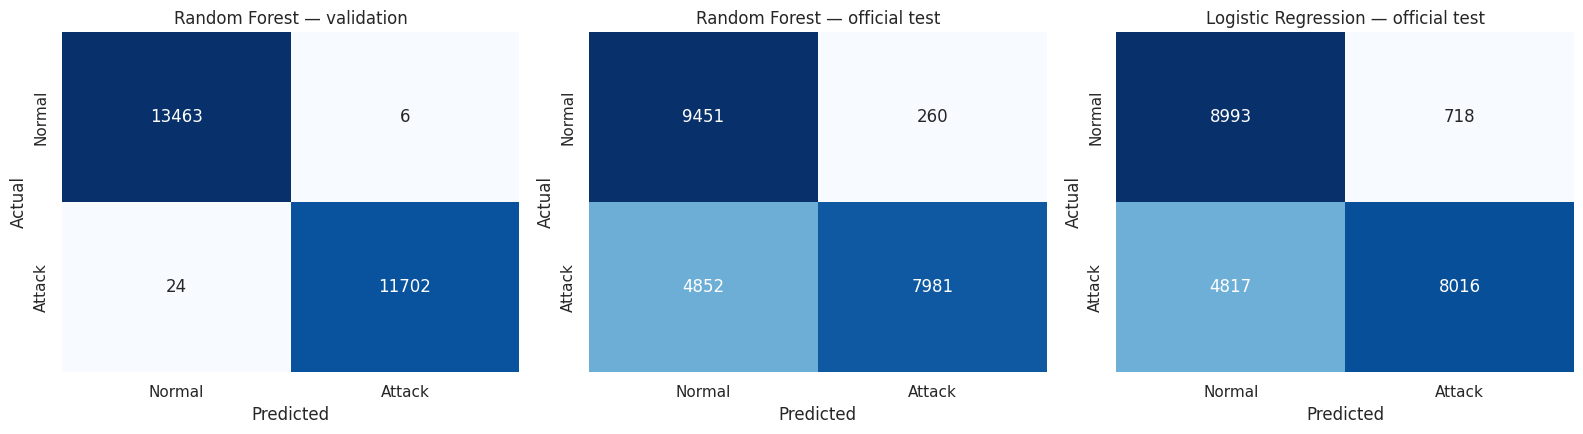

Random Forest on official test set: 7981 attacks caught, 4852 attacks missed (false negatives), 260 normal records flagged as attacks (false positives), 9451 normal records correctly passed.


In [12]:
# Confusion matrices for both models on the official test set + RF on validation
def plot_cm(cm, labels, title, ax, normalize=False):
    cm = np.array(cm)
    data = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1) if normalize else cm
    sns.heatmap(data, annot=True, fmt=".2f" if normalize else "d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(title); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
plot_cm(results["binary"]["Random Forest"]["validation"]["confusion_matrix"], BINARY_NAMES, "Random Forest — validation", axes[0])
plot_cm(results["binary"]["Random Forest"]["test"]["confusion_matrix"],       BINARY_NAMES, "Random Forest — official test", axes[1])
plot_cm(results["binary"]["Logistic Regression"]["test"]["confusion_matrix"], BINARY_NAMES, "Logistic Regression — official test", axes[2])
plt.tight_layout(); save_fig("confusion_matrices_binary.png"); plt.show()

tn, fp, fn, tp = results["binary"]["Random Forest"]["test"]["confusion_matrix"][0] + results["binary"]["Random Forest"]["test"]["confusion_matrix"][1]
print(f"Random Forest on official test set: {tp} attacks caught, {fn} attacks missed (false negatives), "
      f"{fp} normal records flagged as attacks (false positives), {tn} normal records correctly passed.")

## 8. Attack-category (multi-class) classification
Here the Random Forest predicts one of five classes. Because R2L and U2R are rare in training and many R2L attacks in `KDDTest+` are of unseen types, expect
weaker recall on those classes — this is a property of the data and is reported honestly rather than hidden. Look at **per-class** numbers, not just overall accuracy.

In [13]:
def multiclass_metrics(y_true, y_pred):
    rep = classification_report(y_true, y_pred, labels=CATEGORY_ORDER, target_names=CATEGORY_ORDER,
                                zero_division=0, output_dict=True)
    return {"accuracy": float(accuracy_score(y_true, y_pred)),
            "macro_precision": float(rep["macro avg"]["precision"]),
            "macro_recall":    float(rep["macro avg"]["recall"]),
            "macro_f1":        float(rep["macro avg"]["f1-score"]),
            "weighted_f1":     float(rep["weighted avg"]["f1-score"]),
            "per_class": {c: {k: float(rep[c][k]) for k in ("precision", "recall", "f1-score", "support")} for c in CATEGORY_ORDER},
            "confusion_matrix": confusion_matrix(y_true, y_pred, labels=CATEGORY_ORDER).tolist()}

cat_preds = {}
results["multiclass"]["Random Forest"] = {}
for split, X, y in [("validation", X_val, ycat_val), ("test", X_test, ycat_test)]:
    cat_preds[split] = rf_cat.predict(X)
    results["multiclass"]["Random Forest"][split] = multiclass_metrics(y, cat_preds[split])

for split, y in [("validation", ycat_val), ("test", ycat_test)]:
    print(f"===== Multi-class Random Forest — {split.upper()} =====")
    print(classification_report(y, cat_preds[split], labels=CATEGORY_ORDER, digits=4, zero_division=0))

===== Multi-class Random Forest — VALIDATION =====
              precision    recall  f1-score   support

      Normal     0.9980    0.9997    0.9989     13469
         DoS     0.9998    0.9999    0.9998      9186
       Probe     0.9996    0.9940    0.9968      2331
         R2L     1.0000    0.9548    0.9769       199
         U2R     0.8750    0.7000    0.7778        10

    accuracy                         0.9988     25195
   macro avg     0.9745    0.9297    0.9500     25195
weighted avg     0.9988    0.9988    0.9988     25195

===== Multi-class Random Forest — TEST =====
              precision    recall  f1-score   support

      Normal     0.6362    0.9741    0.7697      9711
         DoS     0.9612    0.7733    0.8571      7460
       Probe     0.8638    0.5919    0.7025      2421
         R2L     0.7000    0.0024    0.0048      2885
         U2R     0.4000    0.0299    0.0556        67

    accuracy                         0.7394     22544
   macro avg     0.7122    0.4743  

              precision    recall  f1-score   support

      Normal     0.6362    0.9741    0.7697      9711
         DoS     0.9612    0.7733    0.8571      7460
       Probe     0.8638    0.5919    0.7025      2421
         R2L     0.7000    0.0024    0.0048      2885
         U2R     0.4000    0.0299    0.0556        67

    accuracy                         0.7394     22544
   macro avg     0.7122    0.4743    0.4779     22544
weighted avg     0.7756    0.7394    0.6914     22544



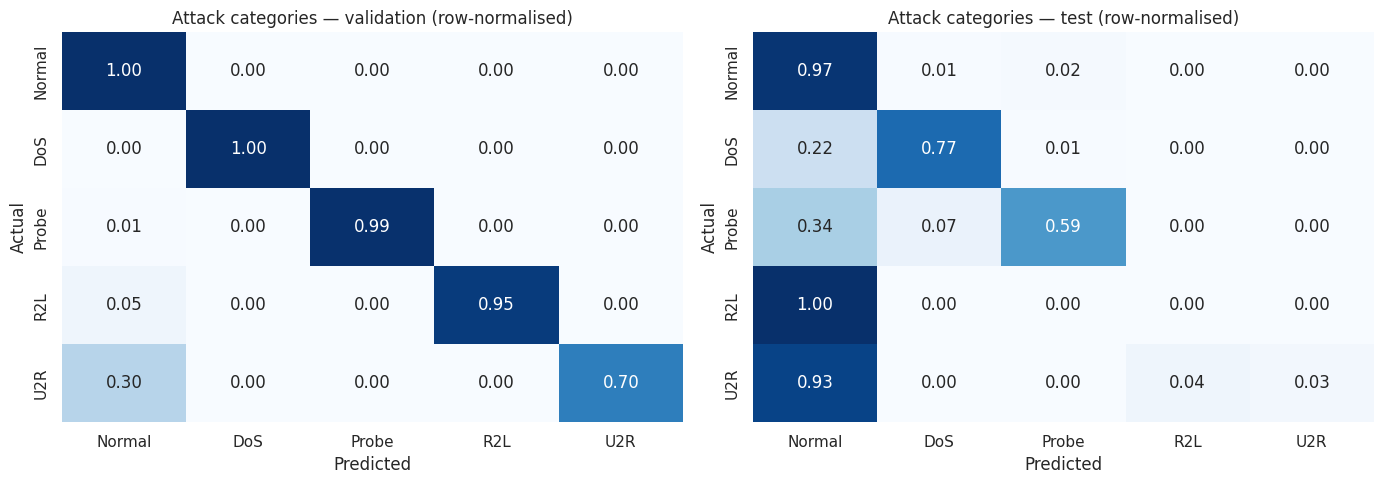

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, split in zip(axes, ["validation", "test"]):
    plot_cm(results["multiclass"]["Random Forest"][split]["confusion_matrix"], CATEGORY_ORDER,
            f"Attack categories — {split} (row-normalised)", ax, normalize=True)
plt.tight_layout(); save_fig("confusion_matrix_multiclass.png"); plt.show()

## 9. Traffic prediction function
`predict_traffic()` accepts a DataFrame of compatible records (the 41 NSL-KDD feature columns), validates it, and returns predictions **produced by the trained models**:

* `prediction` — Normal / Attack (binary model)
* `attack_probability` — the Random Forest's probability of "Attack"
* `predicted_category` — Normal, DoS, Probe, R2L, U2R, or *Unspecified attack* (the binary model says Attack but the category model says Normal)

Incompatible input produces a clear error message instead of a crash.

In [15]:
def predict_traffic(df, binary_model=None, category_model=None):
    binary_model   = binary_model   or rf_bin
    category_model = category_model or rf_cat
    if not isinstance(df, pd.DataFrame) or df.empty:
        raise ValueError("Input must be a non-empty pandas DataFrame.")
    missing = [c for c in FEATURES if c not in df.columns]
    if missing:
        raise ValueError(f"Input is missing {len(missing)} required column(s): {missing[:8]}{' ...' if len(missing) > 8 else ''}. "
                         f"Expected these {len(FEATURES)} columns: {FEATURES}")
    X = df[FEATURES].copy()
    X[NUM_COLS] = X[NUM_COLS].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    bad_rows = int(X[NUM_COLS].isna().any(axis=1).sum())
    if bad_rows:
        raise ValueError(f"{bad_rows} row(s) contain non-numeric, missing or infinite values in numeric columns. Please clean the file.")
    X[CAT_COLS] = X[CAT_COLS].astype(str)

    is_attack = binary_model.predict(X)
    p_attack  = binary_model.predict_proba(X)[:, 1]
    family    = category_model.predict(X)
    category  = np.where(is_attack == 0, "Normal", np.where(family == "Normal", "Unspecified attack", family))
    return pd.DataFrame({"prediction": np.where(is_attack == 1, "Attack", "Normal"),
                         "attack_probability": p_attack.round(4),
                         "predicted_category": category}, index=df.index)

# Demo on 10 random official-test records (labels are NOT given to the model; we only compare afterwards)
demo = test_df.sample(10, random_state=RANDOM_STATE)
demo_pred = predict_traffic(demo)
demo_view = pd.concat([demo[["protocol_type", "service", "flag", "src_bytes"]], demo_pred,
                       demo[["label", "category"]].rename(columns={"label": "actual_label", "category": "actual_category"})], axis=1)
demo_view

,protocol_type,service,flag,src_bytes,prediction,attack_probability,predicted_category,actual_label,actual_category
6186,tcp,smtp,SF,914,Normal,0.00,Normal,normal,Normal
247,tcp,private,S0,0,Attack,1.00,DoS,neptune,DoS
4343,tcp,smtp,SF,1012,Normal,0.00,Normal,normal,Normal
17527,tcp,http,SF,243,Normal,0.00,Normal,normal,Normal
13123,tcp,http,SF,227,Normal,0.00,Normal,normal,Normal
19559,tcp,private,SH,0,Attack,0.99,Probe,nmap,Probe
17794,tcp,http,RSTR,79864,Normal,0.45,Normal,apache2,DoS
11315,tcp,http,SF,259,Normal,0.00,Normal,normal,Normal
11896,tcp,http,SF,233,Normal,0.00,Normal,normal,Normal
15973,tcp,http,SF,235,Normal,0.00,Normal,normal,Normal


In [16]:
# Demonstrate the friendly error handling with a deliberately incompatible input
try:
    predict_traffic(demo[["duration", "protocol_type"]])
except ValueError as err:
    print("Handled as expected ->", str(err)[:230], "...")

Handled as expected -> Input is missing 39 required column(s): ['service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot'] .... Expected these 41 columns: ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_by ...


## 10. Threat-analytics visualisations
All charts below are drawn from the real dataset and the real model outputs. They are for educational analysis only — they say nothing about threats on your own computer or network.

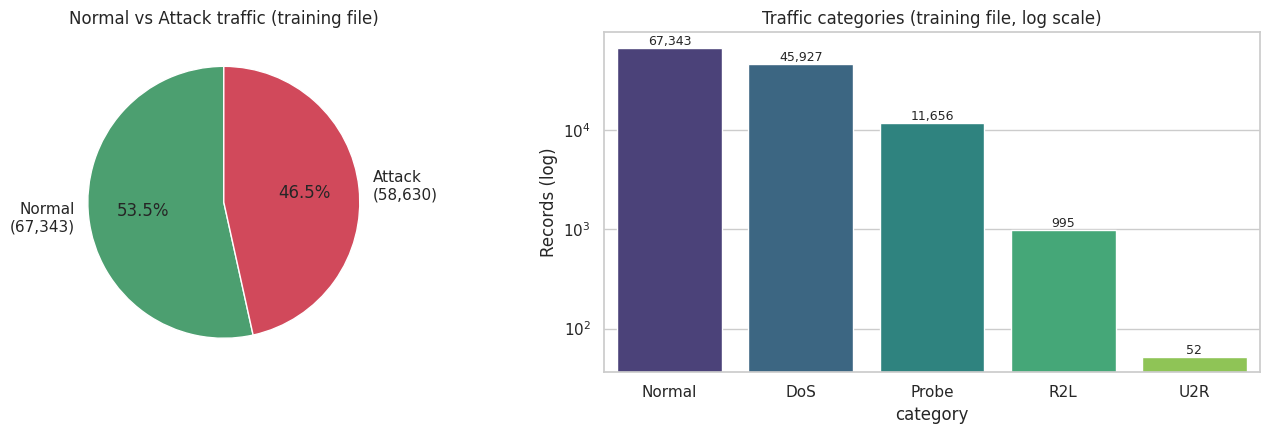

In [17]:
# 10.1 Normal vs Attack, and attack-family distribution (training data)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
bin_counts = train_df["is_attack"].map({0: "Normal", 1: "Attack"}).value_counts().reindex(BINARY_NAMES)
axes[0].pie(bin_counts, labels=[f"{k}\n({v:,})" for k, v in bin_counts.items()], autopct="%1.1f%%",
            colors=["#4C9F70", "#D1495B"], startangle=90, wedgeprops={"edgecolor": "white"})
axes[0].set_title("Normal vs Attack traffic (training file)")
cat_counts = train_df["category"].value_counts().reindex(CATEGORY_ORDER)
sns.barplot(x=cat_counts.index, y=cat_counts.values, ax=axes[1], palette="viridis")
axes[1].set_yscale("log"); axes[1].set_title("Traffic categories (training file, log scale)"); axes[1].set_ylabel("Records (log)")
for i, v in enumerate(cat_counts.values): axes[1].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); save_fig("traffic_distribution.png"); plt.show()

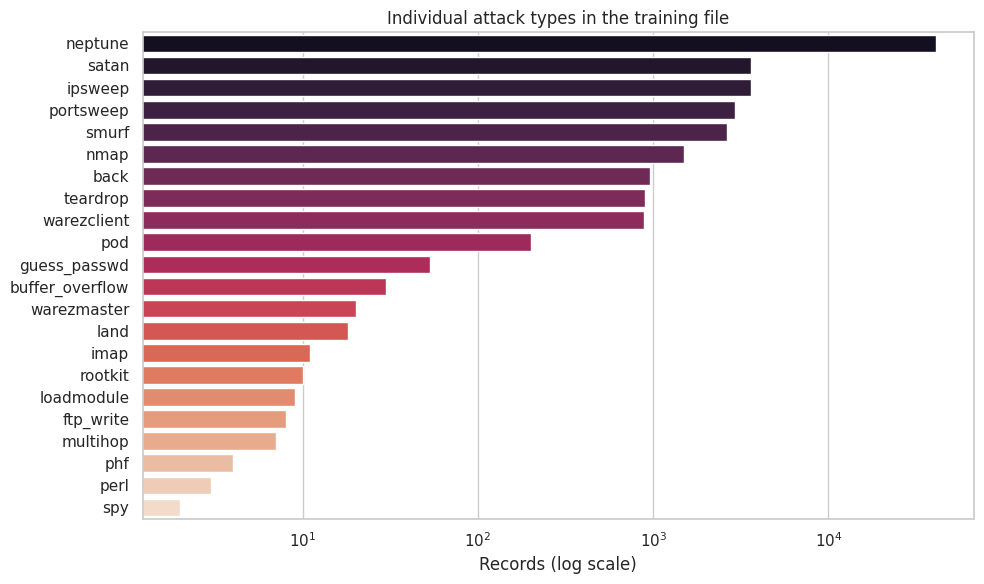

In [18]:
# 10.2 Specific attack names in the training file (excluding 'normal')
attack_counts = train_df.loc[train_df["is_attack"] == 1, "label"].value_counts()
plt.figure(figsize=(10, 6))
sns.barplot(y=attack_counts.index, x=attack_counts.values, palette="rocket")
plt.xscale("log"); plt.xlabel("Records (log scale)"); plt.ylabel("")
plt.title("Individual attack types in the training file")
plt.tight_layout(); save_fig("attack_types.png"); plt.show()

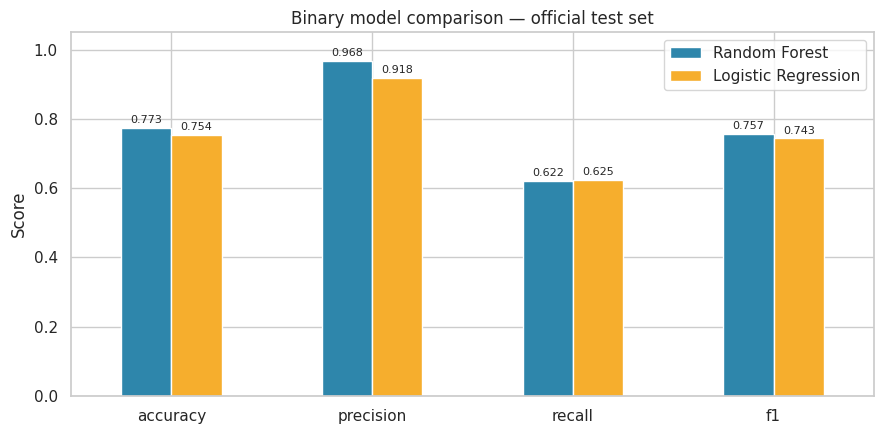

,accuracy,precision,recall,f1
Random Forest,0.7732,0.9685,0.6219,0.7574
Logistic Regression,0.7545,0.9178,0.6246,0.7434


In [19]:
# 10.3 Model performance comparison on the official test set
metrics_to_plot = ["accuracy", "precision", "recall", "f1"]
comp = pd.DataFrame({m: {n: results["binary"][n]["test"][m] for n in results["binary"]} for m in metrics_to_plot})
ax = comp.T.plot(kind="bar", figsize=(9, 4.5), color=["#2E86AB", "#F6AE2D"], rot=0)
ax.set_ylim(0, 1.05); ax.set_title("Binary model comparison — official test set"); ax.set_ylabel("Score")
for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=8, padding=2)
plt.tight_layout(); save_fig("model_comparison.png"); plt.show()
comp.round(4)

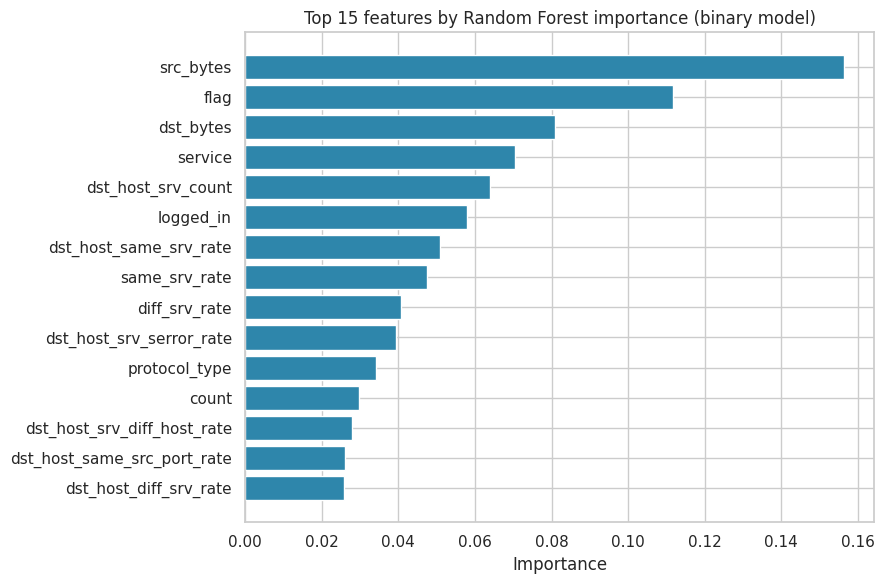

src_bytes                   0.1564
flag                        0.1118
dst_bytes                   0.0809
service                     0.0706
dst_host_srv_count          0.0640
logged_in                   0.0579
dst_host_same_srv_rate      0.0508
same_srv_rate               0.0475
diff_srv_rate               0.0407
dst_host_srv_serror_rate    0.0394
dtype: float64

In [20]:
# 10.4 Which traffic features does the Random Forest rely on most?
pre = rf_bin.named_steps["prep"]
imp = pd.Series(rf_bin.named_steps["model"].feature_importances_, index=pre.get_feature_names_out())
def original_name(n):
    n = n.split("__", 1)[1]
    for c in CAT_COLS:
        if n.startswith(c + "_"): return c        # sum all one-hot columns back into their source feature
    return n
imp_by_feature = imp.groupby(original_name).sum().sort_values(ascending=False)
top = imp_by_feature.head(15)[::-1]
plt.figure(figsize=(9, 6)); plt.barh(top.index, top.values, color="#2E86AB")
plt.title("Top 15 features by Random Forest importance (binary model)"); plt.xlabel("Importance")
plt.tight_layout(); save_fig("feature_importance.png"); plt.show()
results["top_features"] = {k: float(v) for k, v in imp_by_feature.head(10).items()}
imp_by_feature.head(10).round(4)

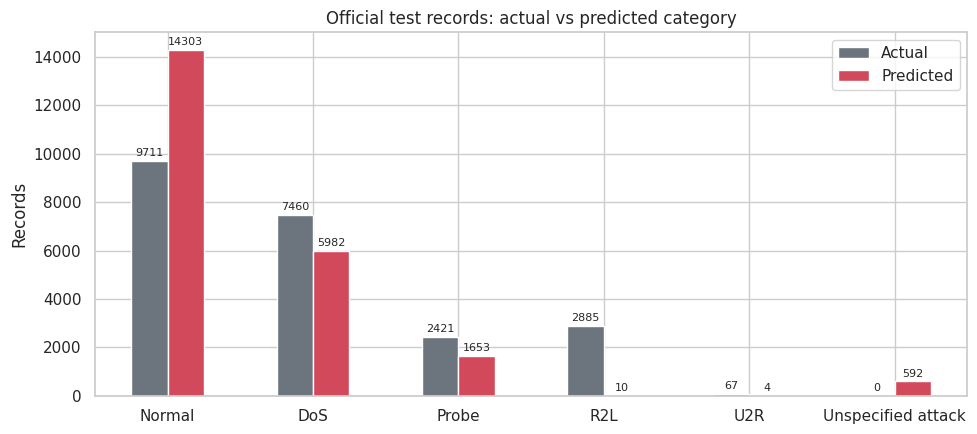

,Actual,Predicted
Normal,9711,14303
DoS,7460,5982
Probe,2421,1653
R2L,2885,10
U2R,67,4
Unspecified attack,0,592


In [21]:
# 10.5 Predicted threat summary for the official test records (using predict_traffic)
test_pred = predict_traffic(test_df)
pred_summary = test_pred["predicted_category"].value_counts()
actual_summary = test_df["category"].value_counts()
order = CATEGORY_ORDER + ["Unspecified attack"]
cmp_df = pd.DataFrame({"Actual": actual_summary, "Predicted": pred_summary}).reindex(order).fillna(0).astype(int)
ax = cmp_df.plot(kind="bar", figsize=(10, 4.5), color=["#6C757D", "#D1495B"], rot=0)
ax.set_title("Official test records: actual vs predicted category"); ax.set_ylabel("Records")
for c in ax.containers: ax.bar_label(c, fontsize=8, padding=2)
plt.tight_layout(); save_fig("predicted_vs_actual_categories.png"); plt.show()
cmp_df

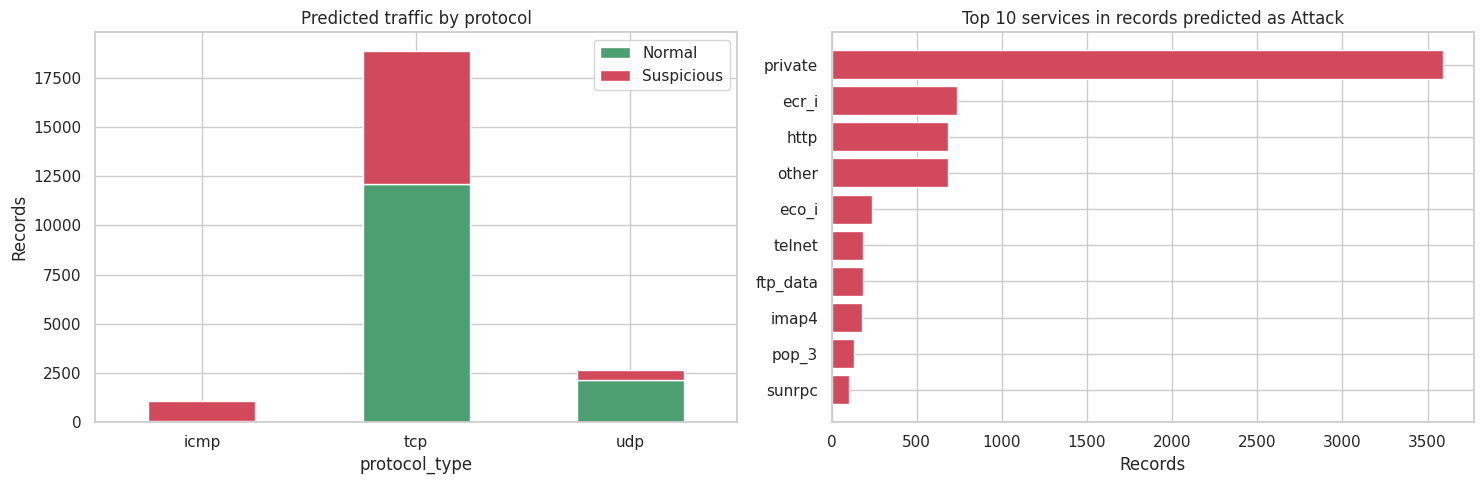

In [22]:
# 10.6 Where does predicted suspicious traffic occur? (protocol and service)
tp_df = pd.concat([test_df[["protocol_type", "service"]], test_pred], axis=1)
tp_df["suspicious"] = (tp_df["prediction"] == "Attack")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
proto = tp_df.groupby("protocol_type")["suspicious"].agg(["sum", "count"])
proto["Normal"] = proto["count"] - proto["sum"]
proto[["Normal", "sum"]].rename(columns={"sum": "Suspicious"}).plot(kind="bar", stacked=True, ax=axes[0], color=["#4C9F70", "#D1495B"], rot=0)
axes[0].set_title("Predicted traffic by protocol"); axes[0].set_ylabel("Records")
top_services = tp_df[tp_df["suspicious"]]["service"].value_counts().head(10)[::-1]
axes[1].barh(top_services.index, top_services.values, color="#D1495B")
axes[1].set_title("Top 10 services in records predicted as Attack"); axes[1].set_xlabel("Records")
plt.tight_layout(); save_fig("suspicious_by_protocol_service.png"); plt.show()

## 11. Save the trained models, metadata and real results
These files are what the Streamlit dashboard (`app.py`) and the project report use — nothing is typed in by hand.

In [23]:
joblib.dump(rf_bin, MODEL_DIR / "rf_binary.joblib", compress=3)
joblib.dump(rf_cat, MODEL_DIR / "rf_category.joblib", compress=3)

metadata = {"dataset": "NSL-KDD (KDDTrain+ / KDDTest+)", "features": FEATURES, "numeric_columns": NUM_COLS,
            "categorical_columns": CAT_COLS, "category_order": CATEGORY_ORDER, "random_state": RANDOM_STATE}
(MODEL_DIR / "model_metadata.json").write_text(json.dumps(metadata, indent=2))

results["dataset"] = {
    "train_records_raw": int(before), "train_records_after_dedup": int(len(train_df)),
    "duplicates_removed_from_train": int(before - len(train_df)),
    "test_records": int(len(test_df)), "n_features": len(FEATURES),
    "train_part": int(len(X_tr)), "validation_part": int(len(X_val)),
    "train_category_counts": {k: int(v) for k, v in train_df["category"].value_counts().items()},
    "test_category_counts":  {k: int(v) for k, v in test_df["category"].value_counts().items()},
    "train_binary_counts": {"Normal": int((train_df.is_attack == 0).sum()), "Attack": int((train_df.is_attack == 1).sum())},
    "test_binary_counts":  {"Normal": int((test_df.is_attack == 0).sum()),  "Attack": int((test_df.is_attack == 1).sum())},
    "unseen_attack_labels_in_test": unseen,
    "test_rows_also_in_train": int(overlap)}
results["training_seconds"] = train_seconds
(OUT_DIR / "metrics.json").write_text(json.dumps(results, indent=2))

# A small, genuine sample of official-test records (with true labels) for trying the dashboard's CSV upload
test_df.sample(300, random_state=RANDOM_STATE)[FEATURES + ["label"]].to_csv(OUT_DIR / "sample_traffic_for_dashboard.csv", index=False)

for f in sorted(list(MODEL_DIR.glob("*")) + list(OUT_DIR.glob("*"))):
    print(f"{f.relative_to(PROJECT_DIR)!s:55s} {f.stat().st_size/1024:9.0f} KB")

models/model_metadata.json                                      2 KB
models/rf_binary.joblib                                      1953 KB
models/rf_category.joblib                                    3584 KB
outputs/attack_types.png                                       68 KB
outputs/confusion_matrices_binary.png                          53 KB
outputs/confusion_matrix_multiclass.png                        77 KB
outputs/feature_importance.png                                 84 KB
outputs/metrics.json                                            6 KB
outputs/model_comparison.png                                   47 KB
outputs/predicted_vs_actual_categories.png                     56 KB
outputs/sample_traffic_for_dashboard.csv                       41 KB
outputs/suspicious_by_protocol_service.png                     75 KB
outputs/traffic_distribution.png                               73 KB


## 12. Limitations and conclusion
* **Dataset age and realism:** NSL-KDD is derived from the 1999 KDD Cup data. Modern traffic and attacks look different, so results do not transfer directly to today's networks.
* **Distribution shift:** `KDDTest+` contains attack types absent from training; scores there are deliberately lower than on the validation part.
* **Class imbalance:** R2L and U2R are rare; their per-class scores are the weakest and should be read with their small support counts in mind.
* **Records, not packets:** the model sees pre-computed connection records, not raw packets or live traffic.
* **No tuning / single split:** results come from one fixed split and default-style hyper-parameters; they are indicative, not definitive.
* **Educational prototype:** SentinelML does not guarantee detection of any attack and must not be used as a production security control.

The code above produced every number, chart, and model file used in the report, README and dashboard.